# 03 – Исследование аномалий KCMA и KSFB.

KCMA – Камарильо и KSFB – Санфорд временно исключены из основной аналитической выборки до завершения проверки. Исходные записи сохранены. Решение согласовано 08 октября 2026 года.

Здесь собраны география, погода, состав самолетов, карты FAA, анализ повторных заходов, графики и методические источники.


In [ ]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Находим папку проекта независимо от места запуска ноутбука
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "north_america" / "reports" / "country_summary.csv").exists())
ORANGE = "#FF6B00"
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 16,
    "text.color": "#253047", "axes.labelcolor": "#536079",
    "xtick.color": "#536079", "ytick.color": "#253047",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.spines.left": False, "axes.spines.bottom": False,
    "figure.facecolor": "white", "axes.facecolor": "white",
    "figure.dpi": 130,
})


## Исследование аномалий: KCMA – Камарильо и KSFB – Санфорд

Группы сохраняются для проверки. KCMA согласован к сохранению, решение по KSFB отложено. Исходные записи не исправляются. Расчеты выполнены по полному региональному CSV 2019 года.

### География и навигационный контекст

| Показатель | KCMA – Камарильо | KSFB – Санфорд |
| --- | --- | --- |
| Расположение | Южная Калифорния, округ Вентура; 34,21° N, 119,09° W | Центральная Флорида, район Орландо; 28,78° N, 81,23° W |
| ВПП по текущей схеме FAA | Одна: 08/26, 6013 × 150 ft | Четыре: 09L/27R, 09C/27C, 09R/27L, 18/36 |
| ILS по каталогу FAA цикла 2610 | В перечне опубликованных процедур ILS нет; RNAV (GPS) и VOR | ILS/LOC для 09L, 09R и 27R |
| Пример профиля | RNAV RWY 08: VDA 3,17°; RNAV Y RWY 26: VDA 3,30° | ILS RWY 09R: GS 3,00° |

География и ВПП проверены по диаграммам FAA. RNAV RWY 08 использует барометрические минимумы LNAV, указанный VDA не является глиссадой ILS. Для RNAV Y RWY 26 отмечено смещение курса относительно ВПП 5,01° и несовпадение угла визуальной системы с указанным углом снижения. Эти особенности текущих процедур не доказывают причину событий 2019 года.

Источник карт: [FAA d-TPP](https://www.faa.gov/air_traffic/flight_info/aeronav/digital_products/dtpp/), цикл 2610, 01–29 октября 2026 года. Скачаны оригинальные PDF и сохранены контрольные суммы в `documents/airports/chart_manifest.json`. Исторические схемы 2019 года пока не получены. Использование конкретной процедуры в CSV не указано.

FAA описывает [KSFB](https://www.faa.gov/flight_deck/sfb) как аэропорт с тремя параллельными ВПП и пересекающей полосой, риском ошибочного выравнивания на полосу и активной летной подготовкой. 09R/27L обозначена как основная учебная ВПП. Это современный контекст, не доказательство назначения отдельного полета.


In [5]:
INVESTIGATION = ROOT / "north_america/reports/airport_investigation"
airport_cases = pd.read_csv(ROOT / "north_america/data/review/kcma_ksfb.csv")
case_summary = pd.DataFrame(json.loads((INVESTIGATION / "summary.json").read_text(encoding="utf-8")))
display(case_summary)
display(pd.read_csv(INVESTIGATION / "runways.csv"))


,airport,rows,go_arounds,unique_aircraft,unique_dates,first_utc,last_utc,observed_months,ga_more_than_two_approaches,max_approaches,missing_typecode,ga_top_five_aircraft
0,KCMA,877,113,435,151,2019-01-02 17:00:55+00:00,2019-12-30 22:11:17+00:00,12,56,14,415,44
1,KSFB,1519,262,235,108,2019-01-26 01:49:26+00:00,2019-12-15 15:44:22+00:00,12,174,13,719,66


,airport,runway,rows,go_arounds,ga_percent
0,KCMA,08,877,113,12.884835
1,KSFB,09C,60,1,1.666667
2,KSFB,09L,656,58,8.841463
3,KSFB,09R,276,94,34.057971
4,KSFB,18,58,24,41.379310
5,KSFB,27C,42,2,4.761905
6,KSFB,27L,82,43,52.439024
7,KSFB,27R,340,38,11.176471
8,KSFB,36,5,2,40.000000


### KCMA – Камарильо: состав выборки

877 записей, 113 с отмеченным уходом (12,9%), 435 бортов, наблюдения в 151 дне. Все записи отнесены к направлению 08. Одностороннее покрытие требует проверки отбора и назначения ВПП, оно не характеризует весь аэропорт.

Тип ВС отсутствует в 415 записях (47,3%), включая 63 из 113 записей с уходом. Среди известных типов: C172 – 141 запись / 32 ухода, P28A – 26 / 6, C182 – 20 / 3. Это поддерживает гипотезу существенной доли легких самолетов, но тип ВС не устанавливает учебное назначение полета.

В 56 из 113 записей с уходом отмечено более двух заходов (49,6%), максимум – 14. Пять наиболее представленных по уходам бортов дают 44 из 113 событий. Повторные заходы и повторные борта требуют отдельной проверки.

Полнота года неоднородна: в июне и июле всего по пять записей, в декабре – 298. Наличие всех 12 месяцев не означает равномерного покрытия.


In [6]:
types = pd.read_csv(INVESTIGATION / "aircraft_types.csv", keep_default_na=False)
display(types.loc[types["airport"].eq("KCMA")].sort_values("rows", ascending=False).head(15))
display(pd.read_csv(INVESTIGATION / "months.csv").query("airport == 'KCMA'"))


,airport,typecode,rows,go_arounds,ga_percent
0,KCMA,,415,63,15.180723
19,KCMA,C172,141,32,22.695035
68,KCMA,P28A,26,6,23.076923
88,KCMA,TBM9,21,0,0.000000
21,KCMA,C182,20,3,15.000000
75,KCMA,PC12,16,0,0.000000
87,KCMA,TBM8,15,0,0.000000
26,KCMA,C25B,13,0,0.000000
6,KCMA,BE20,12,0,0.000000
41,KCMA,CL35,9,0,0.000000


,airport,month,rows,go_arounds,ga_percent
0,KCMA,2019-01,84,3,3.571429
1,KCMA,2019-02,45,7,15.555556
2,KCMA,2019-03,107,10,9.345794
3,KCMA,2019-04,12,3,25.000000
4,KCMA,2019-05,18,4,22.222222
5,KCMA,2019-06,5,2,40.000000
6,KCMA,2019-07,5,3,60.000000
7,KCMA,2019-08,11,7,63.636364
8,KCMA,2019-09,11,4,36.363636
9,KCMA,2019-10,113,13,11.504425


### География ВПП KCMA – оригинальная диаграмма FAA, цикл 2610


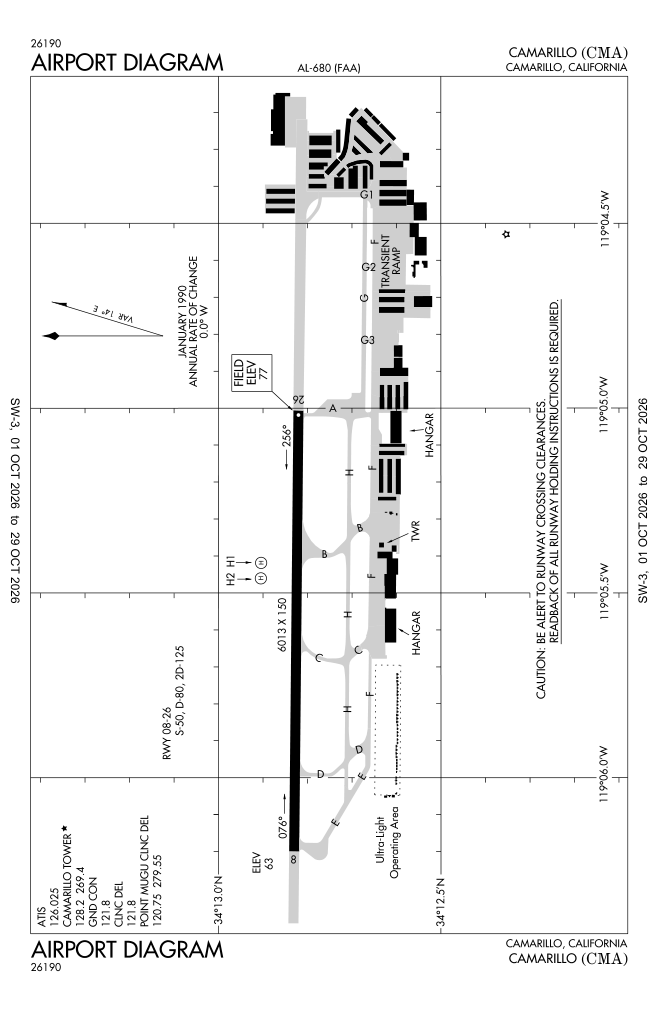

In [ ]:
from IPython.display import Image, display
display(Image(filename=str(ROOT / "north_america/documents/airports/KCMA/files/00680AD.png")))


### RNAV (GPS) RWY 08 – профиль 3,17°, текущая схема


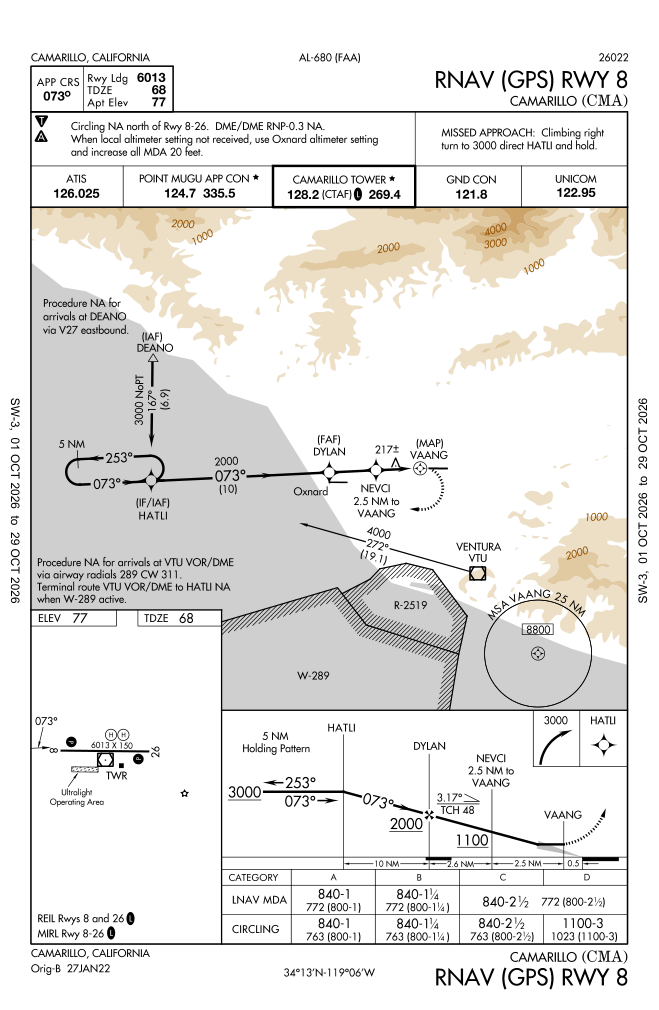

In [ ]:
from IPython.display import Image, display
display(Image(filename=str(ROOT / "north_america/documents/airports/KCMA/files/00680R8.png")))


### RNAV (GPS) Y RWY 26 – профиль 3,30° и смещение курса, текущая схема


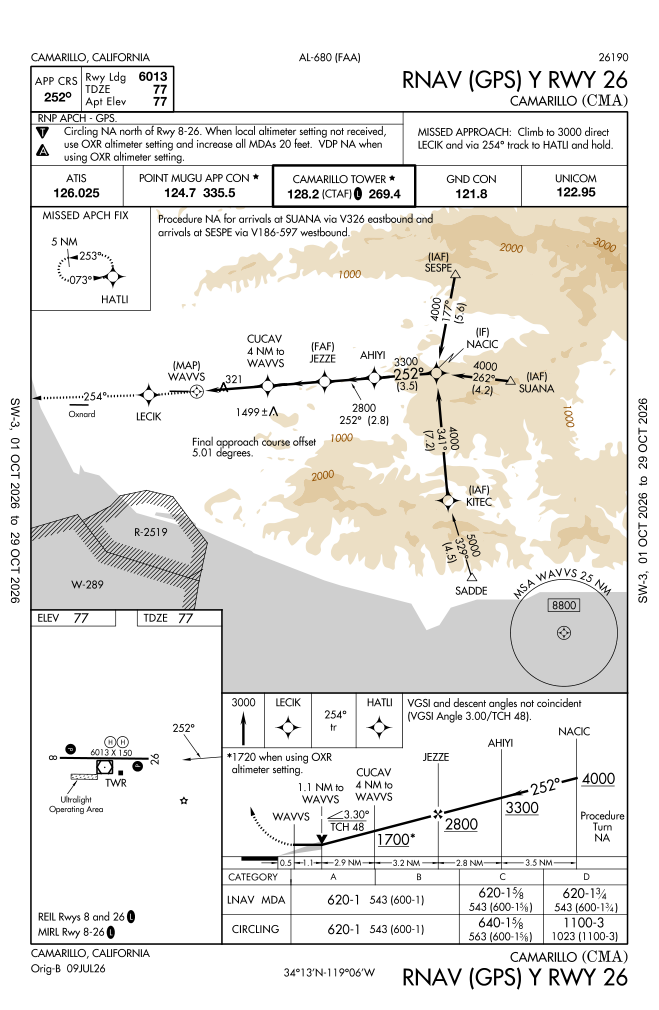

In [ ]:
from IPython.display import Image, display
display(Image(filename=str(ROOT / "north_america/documents/airports/KCMA/files/00680RY26.png")))


### KSFB – Санфорд: состав выборки

1 519 записей, 262 с отмеченным уходом (17,2%), 235 бортов, наблюдения в 108 днях. 1 125 записей относятся к февралю (74,1%). Годовая доля сильно зависит от покрытия этого месяца.

Тип ВС отсутствует в 719 записях (47,3%), включая 152 из 262 записей с уходом. Среди известных типов C172 – 283 записи / 79 уходов, PA44 – 42 / 19, SR20 – 22 / 8. A320 – 202 / 1, A319 – 146 / 0. Объединенная доля маскирует различия состава самолетов; неизвестные типы не относятся автоматически к какой-либо категории.

В 174 из 262 записей с уходом более двух заходов (66,4%), максимум – 13. Пять наиболее представленных по уходам бортов дают 66 событий.

В направлениях 09R/27L зарегистрировано 137 уходов из 358 записей (38,3%), в 09L/27R – 96 из 996 (9,6%). Поле runway относится к итоговой посадке; последовательность использованных ВПП и тип процедуры по нему не устанавливаются.


In [7]:
display(types.loc[types["airport"].eq("KSFB")].sort_values("rows", ascending=False).head(15))
display(pd.read_csv(INVESTIGATION / "months.csv").query("airport == 'KSFB'"))


,airport,typecode,rows,go_arounds,ga_percent
89,KSFB,,719,152,21.140473
105,KSFB,C172,283,79,27.915194
91,KSFB,A320,202,1,0.495050
90,KSFB,A319,146,0,0.000000
132,KSFB,PA44,42,19,45.238095
139,KSFB,SR20,22,8,36.363636
97,KSFB,BE20,15,0,0.000000
126,KSFB,P28A,8,0,0.000000
96,KSFB,B788,6,0,0.000000
101,KSFB,BE40,5,0,0.000000


,airport,month,rows,go_arounds,ga_percent
12,KSFB,2019-01,28,4,14.285714
13,KSFB,2019-02,1125,172,15.288889
14,KSFB,2019-03,167,46,27.544910
15,KSFB,2019-04,9,2,22.222222
16,KSFB,2019-05,14,4,28.571429
17,KSFB,2019-06,32,6,18.750000
18,KSFB,2019-07,22,2,9.090909
19,KSFB,2019-08,16,2,12.500000
20,KSFB,2019-09,25,3,12.000000
21,KSFB,2019-10,30,5,16.666667


### География ВПП KSFB – оригинальная диаграмма FAA, цикл 2610


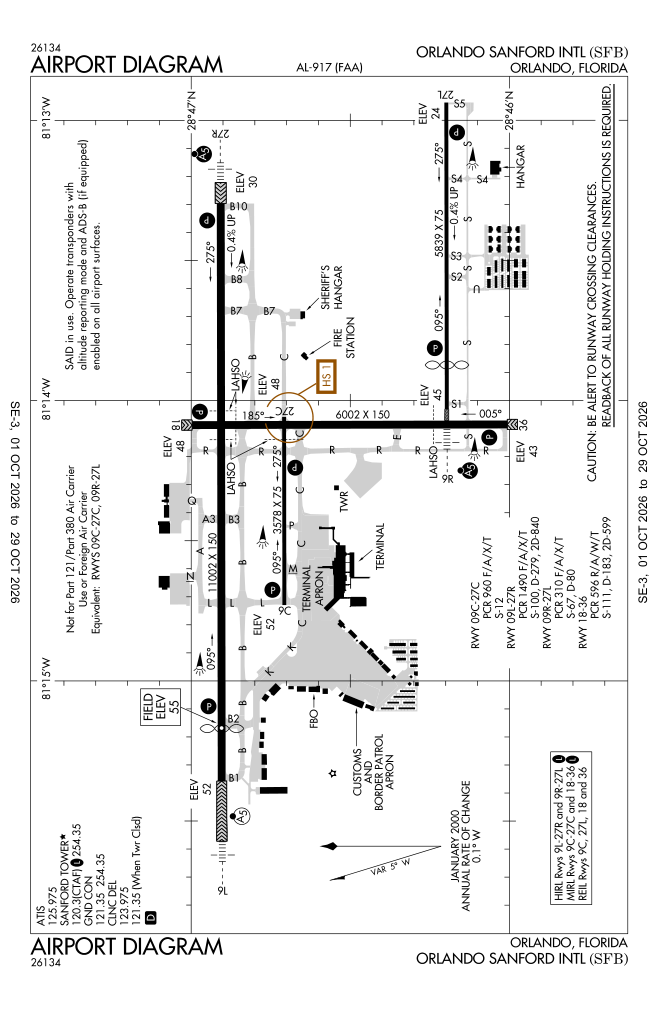

In [ ]:
from IPython.display import Image, display
display(Image(filename=str(ROOT / "north_america/documents/airports/KSFB/files/00917AD.png")))


### ILS or LOC RWY 09R – глиссада 3,00°, текущая схема


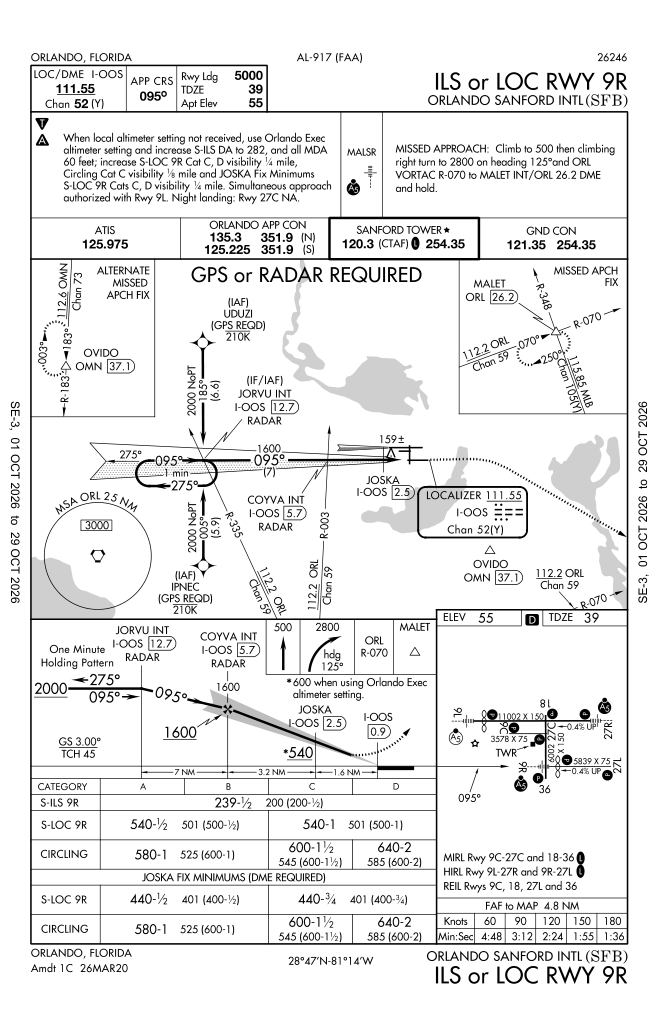

In [ ]:
from IPython.display import Image, display
display(Image(filename=str(ROOT / "north_america/documents/airports/KSFB/files/00917IL9R.png")))


### Погода в записях 2019 года

| Показатель | KCMA без ухода / с уходом | KSFB без ухода / с уходом |
| --- | --- | --- |
| Медиана ветра, узлы | 9 / 7 | 6 / 6 |
| Медиана видимости, м | 16093,44 / 16093,44 | 16093,44 / 16093,44 |
| Медиана температуры, °C | 18,3 / 18,9 | 22,8 / 24,4 |

В записях с уходом KCMA видимость не ниже 6437 м, ветер до 21 узла; KSFB – не ниже 3219 м, ветер до 15 узлов. По этим полям не наблюдается общего преобладания сильного ветра или низкой видимости среди событий. Медианы не исключают отдельные погодные эпизоды.

Порывы указаны лишь в 14 записях с уходом KCMA и пяти KSFB. Их отсутствие не заменяется нулем. Табличная видимость 16093,44 м соответствует 10 статутным милям, но без исходного METAR нельзя установить, было ли значение ограничено кодированием сводки. Потолок облачности и ветер на высоте в CSV отсутствуют.

Это сравнение уже добавленных погодных полей. Исходные METAR для всех полетов этих аэропортов заново не сопоставлялись. Современные METAR со страницы аэропорта не используются для объяснения 2019 года.


In [8]:
weather_columns = ["wind_speed_knts", "wind_gust_knts", "visibility_m", "temperature_deg", "press_p"]
for col in weather_columns:
    airport_cases[col] = pd.to_numeric(airport_cases[col], errors="coerce")
display(airport_cases.groupby(["airport", "has_ga"])[weather_columns].agg(["count", "median", "min", "max"]))


wind_speed_knts                   wind_gust_knts                    visibility_m                               temperature_deg                   press_p                                       
                         count median  min   max          count median   min   max        count    median       min       max           count median  min   max   count       median          min          max
airport has_ga                                                                                                                                                                                                
KCMA    False              763    9.0  0.0  33.0            219   26.0  16.0  48.0          764  16093.44  2816.352  16093.44             764   18.3  5.0  36.7     764  1017.948834  1000.678245  1026.753448
        True               113    7.0  0.0  21.0             14   26.0  16.0  34.0          113  16093.44  6437.376  16093.44             113   18.9  5.0  30.0     113  1016.255639  1004.064635  1025.737531
KSFB    False             1251    6.0  0.0  15.0             52   17.0  14.0  22.0         1257  16093.44  2011.680  16093.44            1257   22.8  9.4  33.3    1257  1019.303390  1009.821498  1028.785282
        True               262    6.0  0.0  15.0              5   17.0  16.0  20.0          262  16093.44  3218.688  16093.44             262   24.4  9.4  30.0     262  1019.642029  1009.821498  1027.769365

### Проверка гипотезы повторных учебных заходов

Авторы [исходного набора](https://zenodo.org/records/7148117) предлагают рассматривать записи с `n_approaches > 2` для отделения учебных и калибровочных полетов. Порог является эвристикой, а не подтверждением цели полета.

Для проверки чувствительности, без изменения CSV: если рассматривать только записи с числом заходов не более двух, KCMA дает 57 уходов из 821 записи (6,9%), KSFB – 88 из 1 345 (6,5%). Доля уменьшается, но остается высокой. Учебные полеты могут иметь и два захода, а эксплуатационный полет – больше двух; автоматическое удаление по этому полю пока не согласовано.

В обоих аэропортах все записи с одним заходом имеют `has_ga=False`, а с двумя и более – `has_ga=True`. Число заходов связано с построением разметки, не является независимым объясняющим признаком и не должно использоваться для предсказания этой метки.

### Предварительный вывод

Ведущие проверяемые гипотезы – смешение разных назначений полетов, особенности покрытия и алгоритма разметки. Текущие схемы не указывают на единый необычно крутой профиль: в примерах VDA 3,17° и 3,30° для KCMA и GS 3,00° для KSFB. Из CSV нельзя установить фактический профиль снижения.

Следующая проверка: траектории и выборочные случаи повторных заходов, назначение полетов, исторические схемы 2019 года и исходные метеосводки. Учебные заходы, touch-and-go и незапланированные уходы должны различаться в будущей базе при наличии подтверждения.

Решения: KCMA сохраняется; по KSFB решение отложено. Значения и состав CSV не изменены.


### KSFB – чувствительность к предполагаемым учебным полетам.

Рабочее предположение: записи с `n_approaches > 2` выделяются как предполагаемые учебные или калибровочные полеты. Основание – рекомендация авторов [набора Zenodo](https://doi.org/10.5281/zenodo.7148117). Назначение каждого полета пока не подтверждено. Связанная публикация: [Monstein et al., 2022](https://doi.org/10.3390/engproc2022028002).

Цель отбора – проверить чувствительность оценки к составу полетов. Снижение доли уходов или погрешности не служит самостоятельным основанием исключения. Все исходные записи сохраняются.

| Сценарий | Кол-во записей | С уходом | Доля, % | Максимальное отклонение Wilson 95%, п.п. |
| --- | ---: | ---: | ---: | ---: |
| Полная выборка KSFB | 1519 | 262 | 17,25 | 1,982 |
| Не более двух заходов | 1345 | 88 | 6,54 | 1,449 |
| Более двух заходов | 174 | 174 | 100,00 | 2,160 |
| Февраль, полная выборка | 1125 | 172 | 15,29 | 2,221 |
| Остальные месяцы, полная выборка | 394 | 90 | 22,84 | 4,396 |
| Остальные месяцы, не более двух заходов | 340 | 36 | 10,59 | 3,722 |

После условного отбора частота снижается на 10,71 п.п., максимальное отклонение – с 1,982 до 1,449 п.п. Допуск 0,2 п.п. все еще превышен примерно в 7,2 раза. Состав группы меняется, поэтому это оценка другой подвыборки, а не исправление исходной частоты.

Все 174 записи с числом заходов больше двух уже имеют метку ухода. Это согласуется с устройством разметки: число заходов не является независимым подтверждением незапланированного ухода. Сто процентов в этой группе не означает, что все полеты были опасными или все были учебными.

Повторные заходы принадлежат 43 бортам. После отбора остаются 228 из 235 бортов: разделяются преимущественно записи полетов, а не целиком самолеты.

### KSFB – ВПП и типы самолетов после условного отбора.

| Группа | Кол-во записей | С уходом | Доля, % |
| --- | ---: | ---: | ---: |
| 09R/27L | 260 | 39 | 15,00 |
| 09L/27R | 947 | 47 | 4,96 |
| C172 | 227 | 23 | 10,13 |
| PA44 | 29 | 6 | 20,69 |
| SR20 | 19 | 5 | 26,32 |
| A319/A320 | 348 | 1 | 0,29 |
| Тип не указан | 617 | 50 | 8,10 |

Различия между направлениями и типами сохраняются. Два захода также могут относиться к учебному полету. Тип самолета и итоговая ВПП не устанавливают цель полета. Малые группы PA44 и SR20 требуют осторожной интерпретации; сравнение не доказывает влияние типа самолета на вероятность ухода.

### KSFB – временное покрытие.

Февраль содержит 74,1% всех записей, но его доля уходов ниже, чем в остальных месяцах: 15,29% против 22,84%. После отбора не более двух заходов вне февраля сохраняется доля 10,59%. Концентрация наблюдений в феврале не объясняет повышенную частоту, однако ограничивает интерпретацию результата как годового показателя.

В феврале выделены 120 записей с более чем двумя заходами, в марте – 33, в остальных месяцах – 21. Для проверки покрытия необходимы независимые сведения о движении аэропорта и условиях приема ADS-B. Кол-во записей в наборе не заменяет фактическую интенсивность полетов.

### Отдельное исследование для диссертации и статьи.

KCMA – Камарильо и KSFB – Санфорд рассматриваются как отдельные случаи неоднородности авиационных данных. План исследования: сопоставление исходных и условно отобранных групп, проверка траекторий, отделение учебных заходов и touch-and-go от незапланированных уходов, учет повторных бортов, временного покрытия, исторических схем и погоды.

Возможная тема статьи: «Влияние учебных полетов и временного покрытия на оценку частоты уходов на второй круг по данным ADS-B». Текущие расчеты составляют предварительный анализ; подтверждение назначения полетов и оценка ошибок разметки необходимы для выводов о причинах.

Решение по KSFB остается отложенным. Условный отбор выполнен только для анализа чувствительности. Состав CSV не изменен.


### KSFB – графики чувствительности.

Условный отбор меняет состав группы. Интервалы Wilson рассчитаны при независимости записей; повторные борта могут нарушать это допущение.


In [ ]:
from pathlib import Path
from statistics import NormalDist
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Путь определяется при запуске из корня проекта или папки ноутбуков
REGION = next(p for p in [Path.cwd() / 'north_america', Path.cwd().parent, Path.cwd()] if (p / 'data/review/kcma_ksfb.csv').exists())
data = pd.read_csv(REGION / 'data/review/kcma_ksfb.csv', keep_default_na=False)
sanford = data.loc[data.airport.eq('KSFB')].copy()
sanford['ga'] = sanford.has_ga.astype(str).str.lower().eq('true')
orange = '#FF6B00'
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 18, 'axes.titlesize': 25, 'axes.labelsize': 20, 'savefig.dpi': 300})

def estimate(group):
    n = len(group)
    k = int(group.ga.sum())
    p = k / n
    z = NormalDist().inv_cdf(0.975)
    divisor = 1 + z*z/n
    center = (p + z*z/(2*n)) / divisor
    half = z * (p*(1-p)/n + z*z/(4*n*n))**0.5 / divisor
    return n, k, p*100, (center-half)*100, (center+half)*100

def style(ax):
    ax.spines[['top', 'right', 'left']].set_visible(False)
    ax.grid(axis='x', color='#E5E7EB', linewidth=1)
    ax.set_axisbelow(True)
    ax.tick_params(axis='y', length=0, pad=16)
    ax.set_xlabel('Доля записей с уходом, %', labelpad=15)

def save_plot(fig, name):
    folder = REGION / 'figures/ksfb'
    folder.mkdir(parents=True, exist_ok=True)
    fig.savefig(folder / (name + '.png'), facecolor='white')
    fig.savefig(folder / (name + '.svg'), facecolor='white')


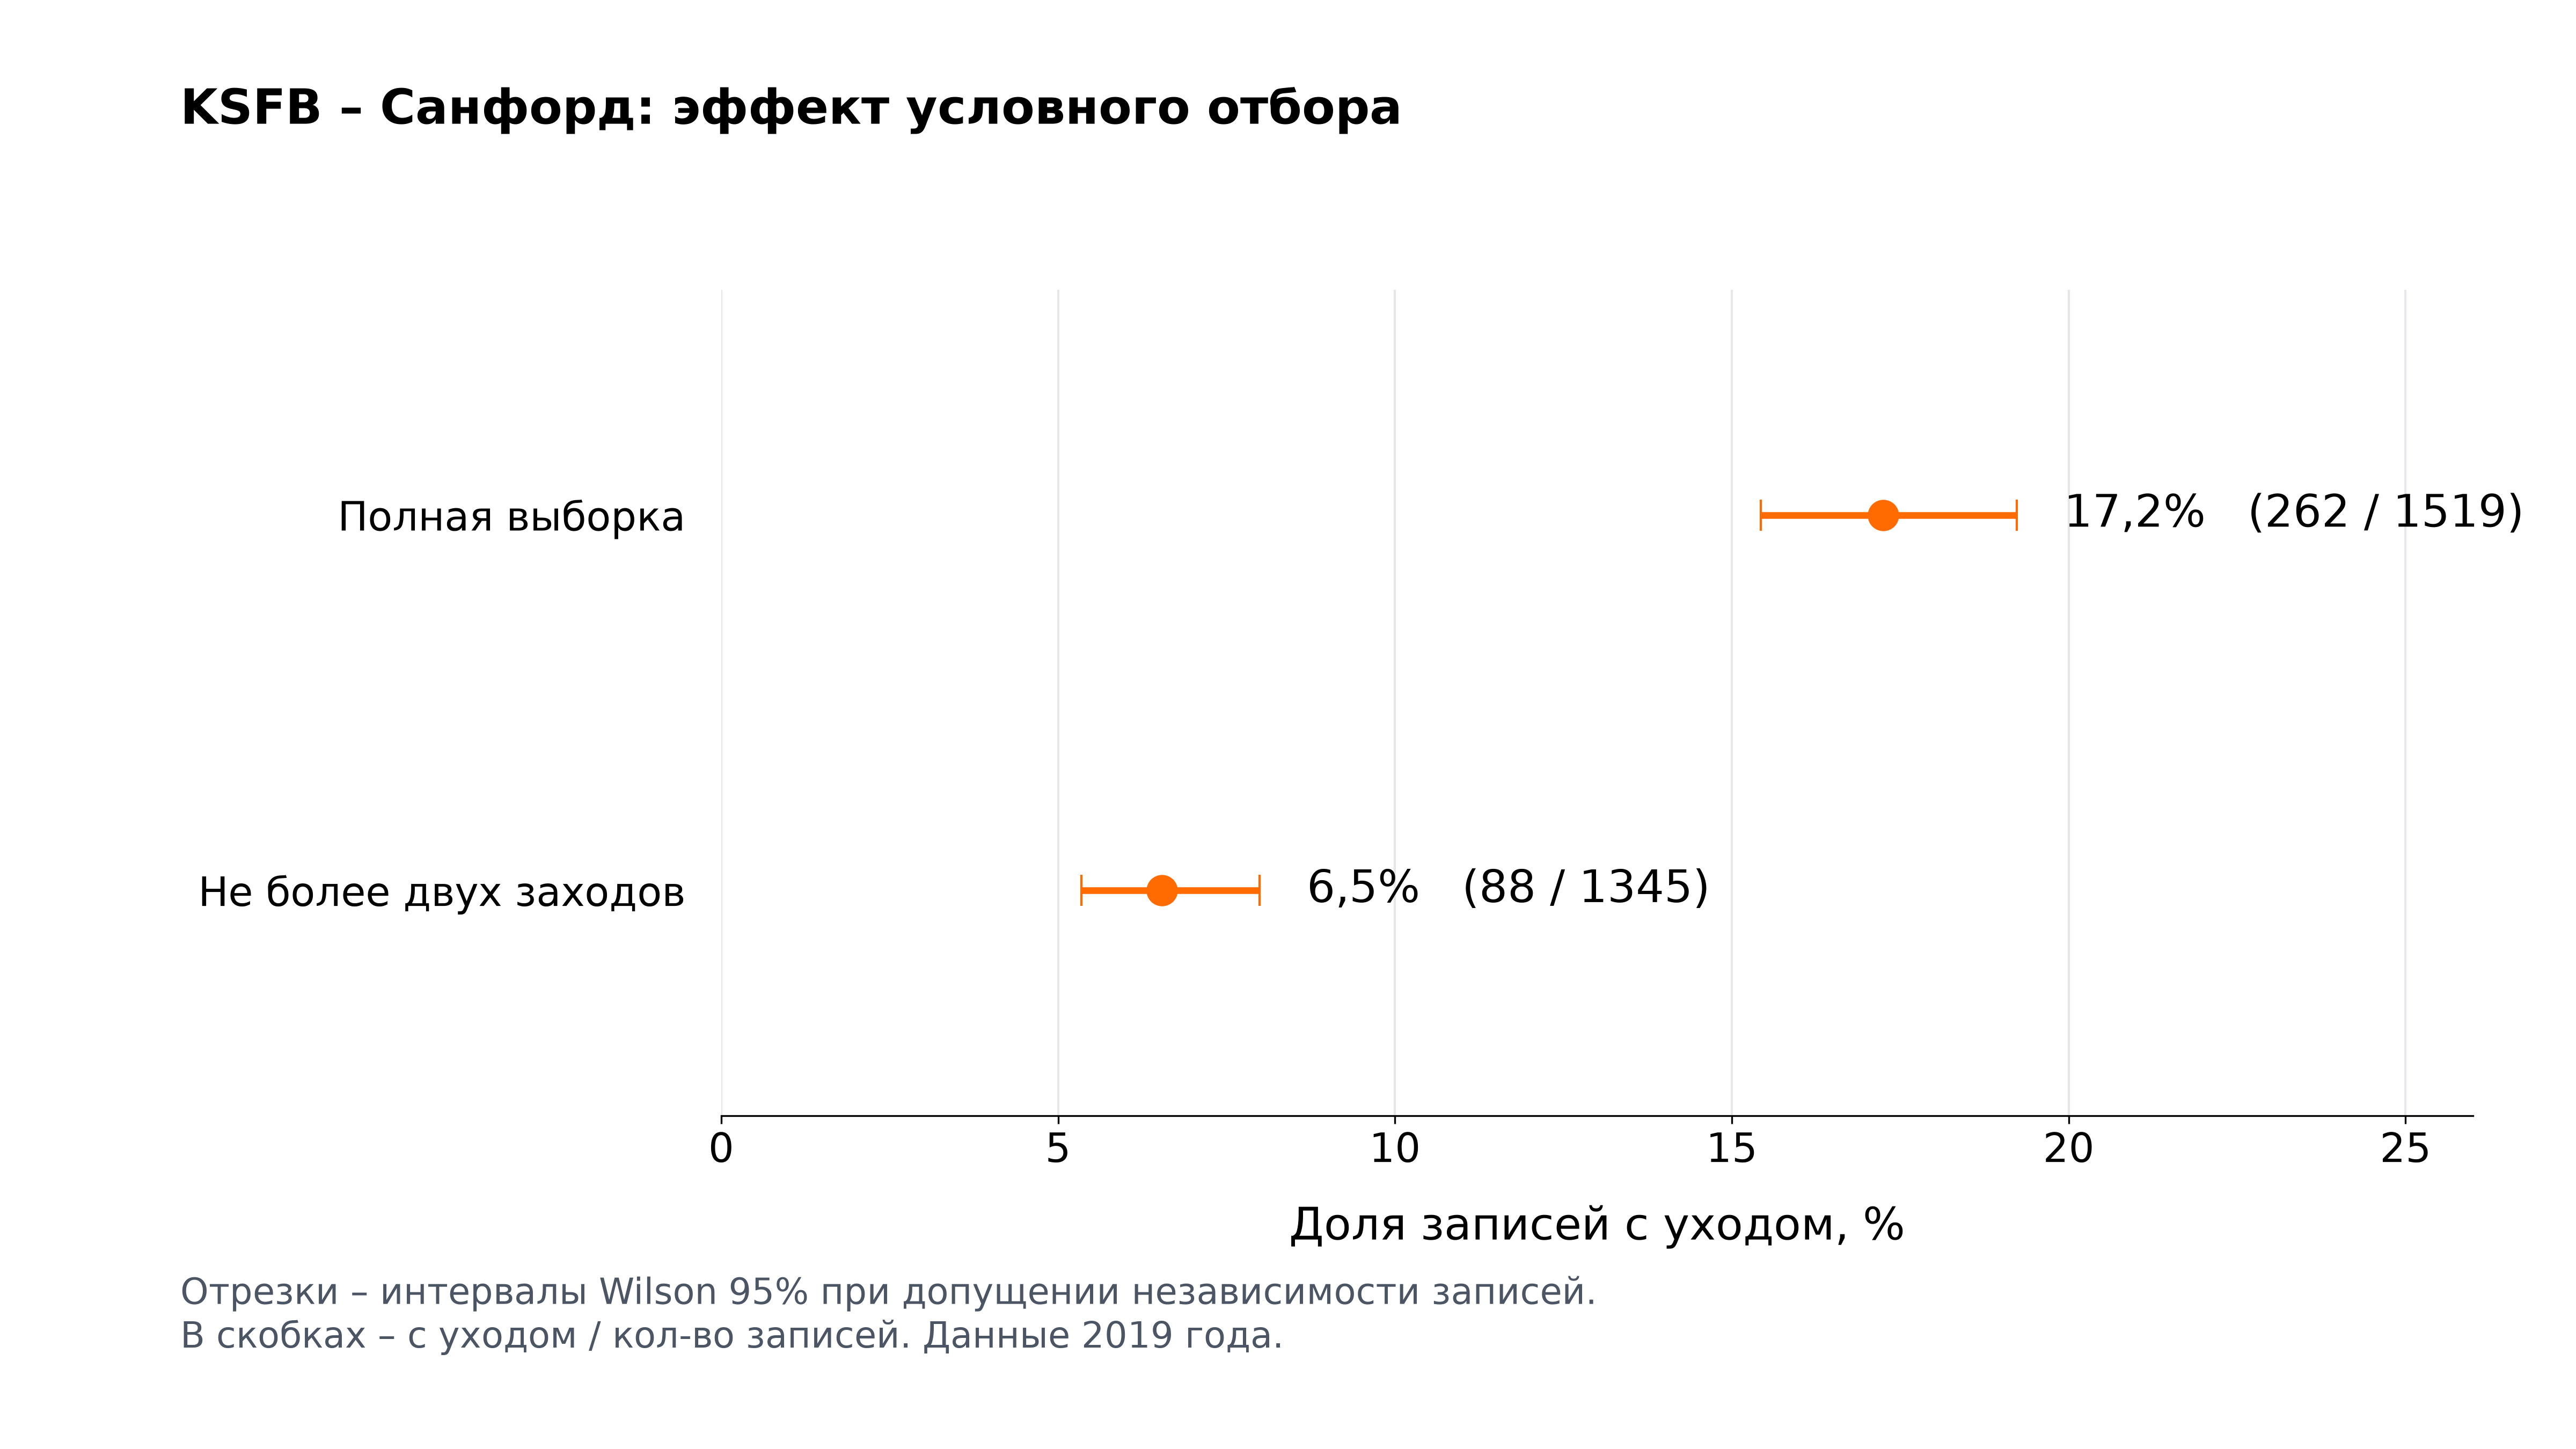

In [ ]:
# KSFB – Санфорд: чувствительность к предполагаемым учебным полетам
groups = [sanford, sanford.loc[sanford.n_approaches.le(2)]]
labels = ['Полная выборка', 'Не более двух заходов']
fig, ax = plt.subplots(figsize=(16, 9))
fig.subplots_adjust(left=0.28, right=0.96, bottom=0.23, top=0.80)
for y, (label, group) in enumerate(zip(labels, groups)):
    n, k, p, low, high = estimate(group)
    ax.errorbar(p, y, xerr=[[p-low], [high-p]], fmt='o', color=orange, markersize=13, linewidth=3, capsize=7)
    ax.text(high+0.7, y, f'{p:.1f}%   ({k} / {n})'.replace('.', ','), va='center', fontsize=20)
ax.set_yticks([0, 1], labels)
ax.set_ylim(1.6, -0.6)
ax.set_xlim(0, 26)
style(ax)
fig.suptitle('KSFB – Санфорд: эффект условного отбора', x=0.07, ha='left', y=0.94, weight='bold')
fig.text(0.07, 0.07, 'Отрезки – интервалы Wilson 95% при допущении независимости записей.\nВ скобках – с уходом / кол-во записей. Данные 2019 года.', fontsize=16, color='#4B5563')
save_plot(fig, '04_selection_sensitivity')
plt.show()


Доля снижается с 17,25% до 6,54%. Максимальное отклонение остается 1,449 п.п., выше допуска 0,2 п.п. Порог точности после отбора не выполнен.


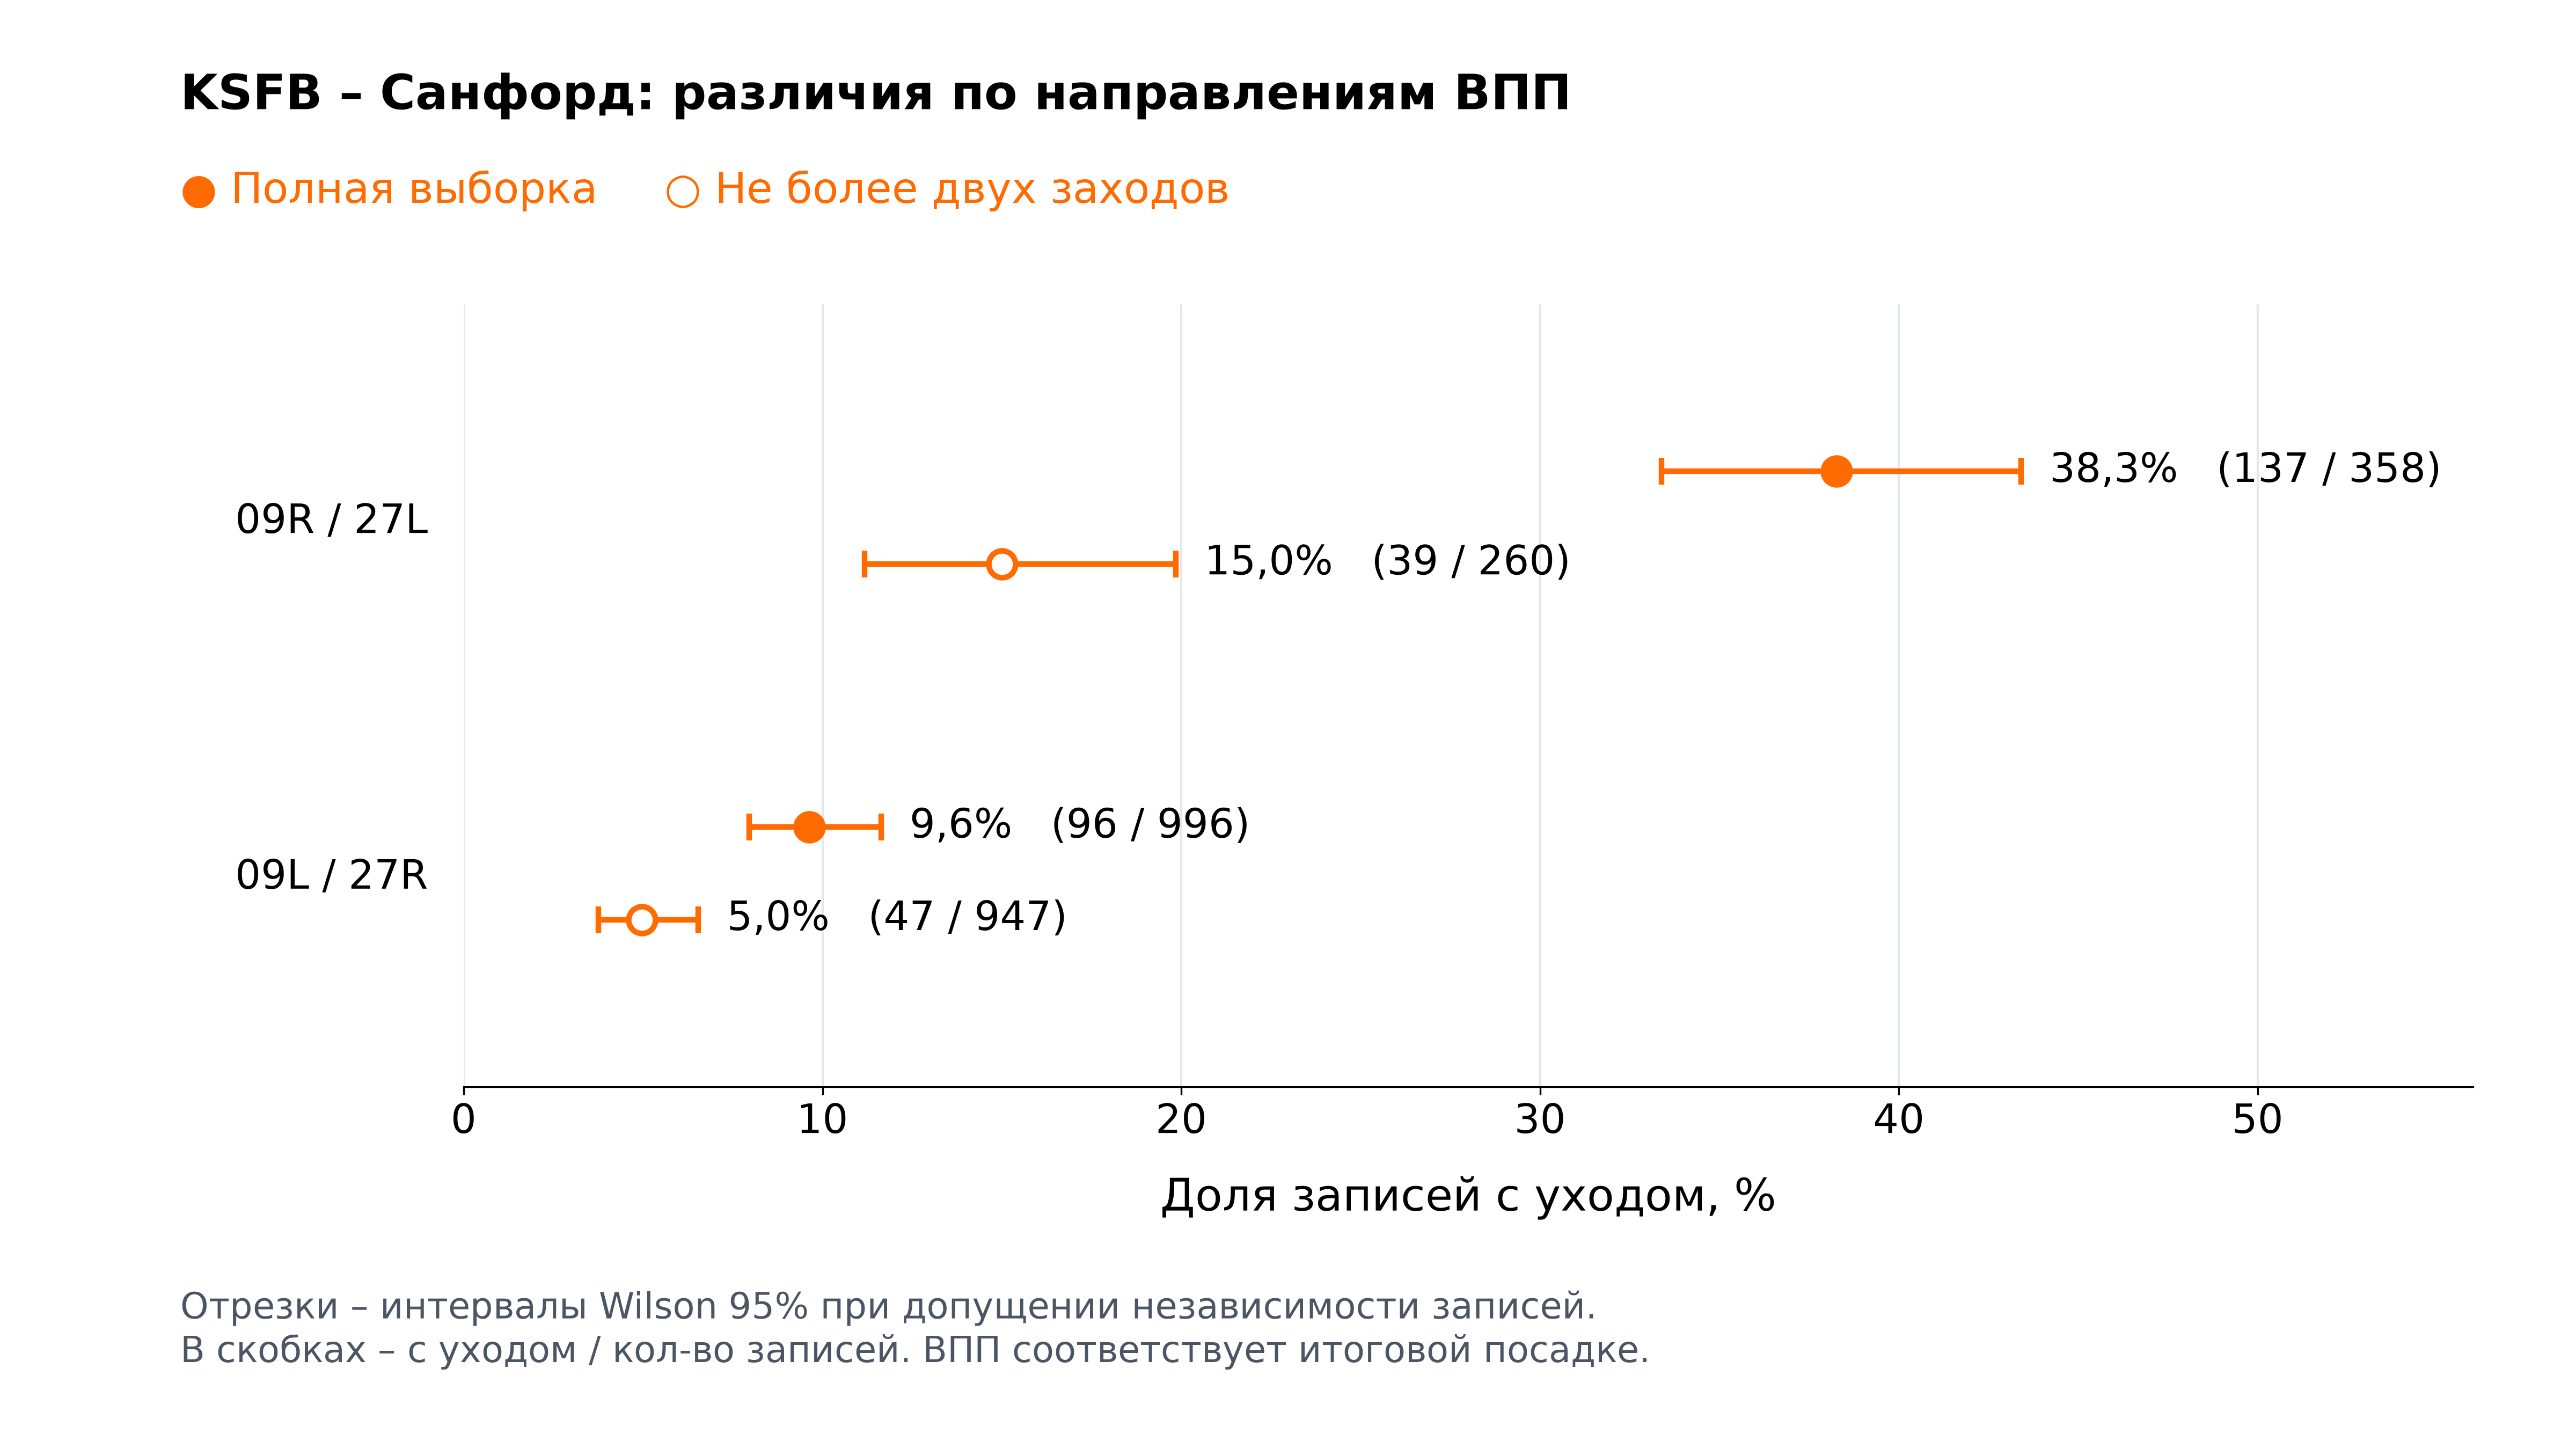

In [ ]:
# KSFB – Санфорд: сравнение направлений итоговой посадки
pairs = [('09R / 27L', ['09R', '27L']), ('09L / 27R', ['09L', '27R'])]
fig, ax = plt.subplots(figsize=(16, 9))
fig.subplots_adjust(left=0.18, right=0.96, bottom=0.25, top=0.79)
for y, (label, runways) in enumerate(pairs):
    group = sanford.loc[sanford.runway.isin(runways)]
    for offset, selected, filled in [(-0.13, group, True), (0.13, group.loc[group.n_approaches.le(2)], False)]:
        n, k, p, low, high = estimate(selected)
        ax.errorbar(p, y+offset, xerr=[[p-low], [high-p]], fmt='o', color=orange, markerfacecolor=orange if filled else 'white', markeredgewidth=2.5, markersize=12, linewidth=2.5, capsize=6)
        ax.text(high+0.8, y+offset, f'{p:.1f}%   ({k} / {n})'.replace('.', ','), va='center', fontsize=18)
ax.set_yticks([0, 1], [p[0] for p in pairs])
ax.set_ylim(1.6, -0.6)
ax.set_xlim(0, 56)
style(ax)
fig.suptitle('KSFB – Санфорд: различия по направлениям ВПП', x=0.07, ha='left', y=0.95, weight='bold')
fig.text(0.07, 0.86, '● Полная выборка     ○ Не более двух заходов', fontsize=19, color=orange)
fig.text(0.07, 0.06, 'Отрезки – интервалы Wilson 95% при допущении независимости записей.\nВ скобках – с уходом / кол-во записей. ВПП соответствует итоговой посадке.', fontsize=16, color='#4B5563')
save_plot(fig, '05_runway_comparison')
plt.show()


После условного отбора доля в направлениях 09R/27L составляет 15,00%, в 09L/27R – 4,96%. Различие сохраняется, но назначение каждого полета и влияние смешения типов самолетов пока не установлены.

### Рекомендация по использованию KSFB.

Сохранить KSFB в базе и в отдельном исследовании аномалий. До проверки назначения полетов и разметки не включать его в основное сравнение частот незапланированных уходов между аэропортами и обучение модели этого события. Высокая доля сама по себе не является причиной исключения. Основания ограничения: неподтвержденное смешение назначений полетов, неравномерное временное покрытие и превышение согласованного допуска точности.

Рекомендация вынесена на согласование. Исходные записи и аналитический CSV не изменены. Отбор по числу заходов остается сценарием чувствительности. Для возвращения в основной анализ требуются проверка траекторий, оценка ошибок разметки и повторная оценка точности для подтвержденной целевой группы.


### Методические источники по обработке аномалий.

Разбор подходов ML и ссылки сохранены в [методической записке](../reports/airport_investigation/ml_methodology.md). Превышение допуска точности частоты не является самостоятельным доказательством непригодности записей для ML. Для KSFB главное ограничение – неподтвержденное соответствие метки целевому событию.


## Решение по основной выборке.

KCMA – Камарильо и KSFB – Санфорд временно исключены из основной аналитической выборки до завершения проверки. Исходные записи сохранены. Решение согласовано 08 октября 2026 года.

Высокая частота сама по себе не является основанием удаления. Требуется проверить назначение полетов, разметку и покрытие. Условный отбор по числу заходов остается анализом чувствительности.

## Кол-во заходов и уходов.

`n_approaches` – кол-во выявленных заходов, а не кол-во уходов. Порог Zenodo `n_approaches > 2` предложен для предполагаемых учебных и калибровочных полетов. Универсальное правило обязательного ухода на запасной после двух уходов для всех рассматриваемых полетов не подтверждено. [FAA AIM 5-4-21, пункт 6](https://www.faa.gov/Air_traffic/Publications/atpubs/aim_html/chap5_section_4.html) предусматривает запрос разрешения на дальнейшие действия, включая другой заход или следование на запасной. Возможные ограничения конкретного эксплуатанта требуют отдельного документа.
